# 1997 — Long Short-Term Memory (LSTM)

**Paper:** Sepp Hochreiter & Jürgen Schmidhuber, *"Long Short-Term Memory"* (1997). The forget gate came from Gers, Schmidhuber & Cummins (2000).

Plain RNNs multiply the gradient by $W_{hh}$ at every step, so it **vanishes** (or explodes) over long sequences (Hochreiter 1991; Bengio et al. 1994). The LSTM adds a **cell state** $c_t$ that is updated *additively* and controlled by gates:

$$
\begin{aligned}
i_t,\ f_t,\ o_t &= \sigma(W_{\{i,f,o\}}[x_t, h_{t-1}] + b) && \text{input, forget, output gates}\\
\tilde c_t &= \tanh(W_c[x_t,h_{t-1}] + b_c)\\
c_t &= f_t \odot c_{t-1} + i_t \odot \tilde c_t && \text{the "constant error carousel"}\\
h_t &= o_t \odot \tanh(c_t)
\end{aligned}
$$

We (1) write the cell by hand and check it matches `nn.LSTM`, then (2) run the **adding problem** from the original paper, where a vanilla RNN fails and an LSTM succeeds.

![Diagram: LSTM (Hochreiter & Schmidhuber, 1997)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/13_1997_lstm.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
class LSTMCell(nn.Module):
    def __init__(self, n_in, n_hid):
        super().__init__()
        self.x2g = nn.Linear(n_in, 4 * n_hid)
        self.h2g = nn.Linear(n_hid, 4 * n_hid)

    def forward(self, x, state):
        h, c = state
        i, f, g, o = (self.x2g(x) + self.h2g(h)).chunk(4, -1)   # same gate order as PyTorch
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

# Check against PyTorch's optimized implementation by copying weights
cell, ref = LSTMCell(3, 5), nn.LSTM(3, 5, batch_first=True)
with torch.no_grad():
    cell.x2g.weight.copy_(ref.weight_ih_l0); cell.x2g.bias.copy_(ref.bias_ih_l0)
    cell.h2g.weight.copy_(ref.weight_hh_l0); cell.h2g.bias.copy_(ref.bias_hh_l0)
x = torch.randn(2, 7, 3)
h = c = torch.zeros(2, 5)
for t in range(7): h, c = cell(x[:, t], (h, c))
print("max difference vs nn.LSTM:", (h - ref(x)[0][:, -1]).abs().max().item())

max difference vs nn.LSTM: 0.0


## The adding problem
Each input step has two channels: a random number in [0,1] and a marker. Exactly two steps are marked — one in the first half, one in the second. The target is the **sum of the two marked numbers**, read out at the last step. Always predicting 1.0 gives MSE ≈ 0.167, so anything below that means the model is remembering across the gap.

RNN  final MSE ≈ 0.1700
LSTM final MSE ≈ 0.0112


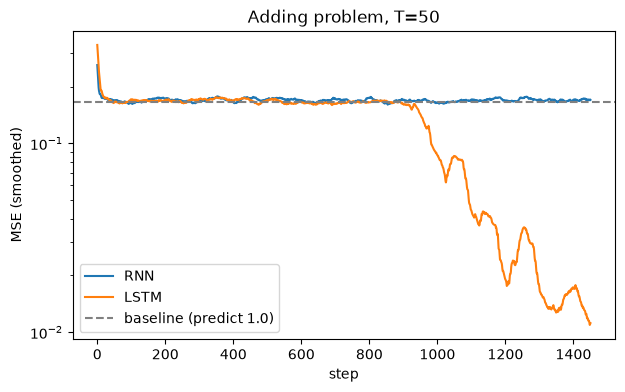

In [3]:
def adding_batch(B, T):
    vals = torch.rand(B, T)
    mark = torch.zeros(B, T)
    a = torch.randint(0, T // 2, (B,)); b = torch.randint(T // 2, T, (B,))
    mark[torch.arange(B), a] = 1; mark[torch.arange(B), b] = 1
    y = (vals * mark).sum(1, keepdim=True)
    return torch.stack([vals, mark], -1).to(device), y.to(device)

class SeqRegressor(nn.Module):
    def __init__(self, kind, hidden=64):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM}[kind](2, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        return self.head(self.rnn(x)[0][:, -1])

def train(kind, T, steps=1500):
    seed_everything(0)
    m = SeqRegressor(kind).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=2e-3)
    curve = []
    for s in range(steps):
        x, y = adding_batch(64, T)
        loss = F.mse_loss(m(x), y)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        curve.append(loss.item())
    return np.convolve(curve, np.ones(50) / 50, mode="valid")

T = 50
curves = {k: train(k, T) for k in ["RNN", "LSTM"]}
for k, c in curves.items(): print(f"{k:4s} final MSE ≈ {c[-1]:.4f}")
plt.figure(figsize=(7, 4))
for k, c in curves.items(): plt.plot(c, label=k)
plt.axhline(1 / 6, ls="--", c="gray", label="baseline (predict 1.0)")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("MSE (smoothed)"); plt.title(f"Adding problem, T={T}"); plt.legend(); plt.show()

## Why it works: gradients through time
Measure $\|\partial \mathcal L / \partial x_t\|$ for each input step. The RNN's gradient decays exponentially going back in time; the LSTM's cell state keeps it alive.

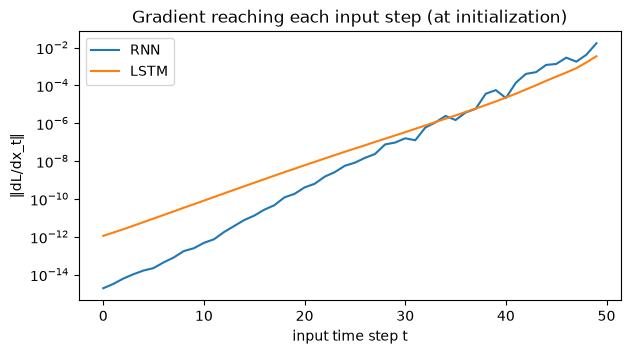

In [4]:
def grad_profile(kind, T=50):
    seed_everything(1)
    m = SeqRegressor(kind).to(device)
    x, y = adding_batch(32, T); x.requires_grad_(True)
    F.mse_loss(m(x), y).backward()
    return x.grad.norm(dim=(0, 2)).cpu()
plt.figure(figsize=(7, 3.5))
for k in ["RNN", "LSTM"]: plt.semilogy(grad_profile(k), label=k)
plt.xlabel("input time step t"); plt.ylabel("‖dL/dx_t‖"); plt.title("Gradient reaching each input step (at initialization)"); plt.legend(); plt.show()